# Coin Detection, Classification and Counting
## Image Processing and Computer Vision — Assignment Module #1

**Part 1 — Detection.** Given a target image, find every coin in it and return its centre and
radius. Classification of the denomination and the monetary total are addressed separately.

Traditional computer vision only. The pipeline has five stages:

1. denoising and colour correction
2. candidate circles from the Hough transform on the luminance channel
3. verification of each candidate by the radial support of the image gradient
4. suppression of duplicate detections
5. a physical constraint on the admissible radii

An earlier version of this pipeline carried three further mechanisms. All three were measured and
removed; section 8.2 records what each was worth.

---
## 1. Setup

Paths assume the dataset has been unzipped into `./coin_dataset`.

In [1]:
import os, json, time, glob, hashlib
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (12, 9)

DATA_DIR  = 'coin_dataset'
REF_DIR   = os.path.join(DATA_DIR, 'reference_set')
TGT_DIR   = os.path.join(DATA_DIR, 'target_set')
CACHE_DIR = 'denoised_cache'
CAND_FILE = 'candidates.json'

N_IMAGES = 142

COIN_VALUES = {'1cent': 0.01, '2cent': 0.02, '5cent': 0.05, '10cent': 0.10,
               '20cent': 0.20, '50cent': 0.50, '1euro': 1.00, '2euro': 2.00}

# Official diameters in mm, used below as a physical constraint on the detections.
COIN_MM = {'1cent': 16.25, '2cent': 18.75, '5cent': 21.25, '10cent': 19.75,
           '20cent': 22.25, '50cent': 24.25, '1euro': 23.25, '2euro': 25.75}

MAX_DIAMETER_RATIO = COIN_MM['2euro'] / COIN_MM['1cent']

print(f'Largest / smallest euro coin diameter ratio: {MAX_DIAMETER_RATIO:.3f}')

Largest / smallest euro coin diameter ratio: 1.585


---
## 2. Ground truth

The target set ships without labels. To make design decisions measurable rather than visual, the
number of coins in each of the 142 target images was annotated by hand. This is weak supervision
— it constrains counts, not positions — so it is used as a *scoring function for design choices*,
while localisation quality is assessed separately.

In [2]:
GROUND_TRUTH = {
    1: 3, 2: 1, 3: 6, 4: 1, 5: 1, 6: 1, 7: 3, 8: 1,
    9: 1, 10: 1, 11: 2, 12: 2, 13: 1, 14: 1, 15: 1, 16: 2,
    17: 3, 18: 3, 19: 1, 20: 3, 21: 1, 22: 1, 23: 2, 24: 3,
    25: 3, 26: 2, 27: 5, 28: 2, 29: 1, 30: 3, 31: 2, 32: 3,
    33: 1, 34: 1, 35: 1, 36: 2, 37: 3, 38: 7, 39: 2, 40: 5,
    41: 1, 42: 1, 43: 2, 44: 2, 45: 3, 46: 3, 47: 3, 48: 1,
    49: 3, 50: 2, 51: 4, 52: 6, 53: 1, 54: 2, 55: 2, 56: 1,
    57: 3, 58: 3, 59: 2, 60: 1, 61: 1, 62: 2, 63: 3, 64: 1,
    65: 1, 66: 3, 67: 2, 68: 1, 69: 1, 70: 1, 71: 1, 72: 3,
    73: 3, 74: 2, 75: 2, 76: 4, 77: 3, 78: 3, 79: 5, 80: 2,
    81: 1, 82: 1, 83: 1, 84: 4, 85: 5, 86: 3, 87: 1, 88: 6,
    89: 2, 90: 2, 91: 1, 92: 3, 93: 1, 94: 3, 95: 3, 96: 8,
    97: 4, 98: 4, 99: 1, 100: 1, 101: 3, 102: 3, 103: 3, 104: 1,
    105: 1, 106: 3, 107: 1, 108: 1, 109: 2, 110: 2, 111: 3, 112: 3,
    113: 1, 114: 1, 115: 4, 116: 1, 117: 1, 118: 8, 119: 1, 120: 2,
    121: 4, 122: 3, 123: 1, 124: 3, 125: 2, 126: 3, 127: 2, 128: 3,
    129: 1, 130: 2, 131: 1, 132: 4, 133: 3, 134: 2, 135: 1, 136: 2,
    137: 3, 138: 3, 139: 2, 140: 2, 141: 1, 142: 2,
}

assert len(GROUND_TRUTH) == N_IMAGES
print(f'{len(GROUND_TRUTH)} images annotated, {sum(GROUND_TRUTH.values())} coins in total')
print('coins per image:', {k: sum(1 for v in GROUND_TRUTH.values() if v == k)
                           for k in sorted(set(GROUND_TRUTH.values()))})

142 images annotated, 328 coins in total
coins per image: {1: 52, 2: 33, 3: 39, 4: 8, 5: 4, 6: 3, 7: 1, 8: 2}


---
## 3. Characterising the degradation

Before choosing any filter it is worth measuring what is wrong with the images. Two properties of
the target set differ sharply from the reference set.

### 3.1 Noise

Noise standard deviation is estimated with the method of Immerkaer (1996): convolving with a
kernel that annihilates locally linear intensity and averaging the absolute response. The kernel
is the difference of two Laplacians, so it responds to noise while cancelling smooth content.

The estimator cannot tell noise from fine texture — both are high-frequency — so its readings on
textured backgrounds are inflated. Section 10 returns to this point, which caused a real error
during development.

In [3]:
def estimate_noise_sigma(gray, mask=None):
    """Immerkaer's estimator of the standard deviation of additive Gaussian noise.
    With a boolean mask, the estimate is restricted to the selected pixels."""
    M = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)
    response = np.abs(cv2.filter2D(gray.astype(np.float32), -1, M))
    if mask is None:
        H, W = gray.shape
        return response.sum() * np.sqrt(0.5 * np.pi) / (6.0 * (W - 2) * (H - 2))
    return float(response[mask].mean()) * np.sqrt(np.pi / 2) / 6.0


print(f'{"image":<20}{"sigma":>8}{"lap.var":>10}')
for name in ['1cent', '10cent', '1euro']:
    g = cv2.imread(os.path.join(REF_DIR, name + '.jpg'), cv2.IMREAD_GRAYSCALE)
    print(f'{"reference/" + name:<20}{estimate_noise_sigma(g):8.2f}'
          f'{cv2.Laplacian(g, cv2.CV_64F).var():10.1f}')
for i in [1, 43, 85]:
    g = cv2.imread(os.path.join(TGT_DIR, f'image_{i}.jpg'), cv2.IMREAD_GRAYSCALE)
    print(f'{"target/image_" + str(i):<20}{estimate_noise_sigma(g):8.2f}'
          f'{cv2.Laplacian(g, cv2.CV_64F).var():10.1f}')

image                  sigma   lap.var
reference/1cent         0.32      30.2
reference/10cent        0.43      57.0
reference/1euro         0.57     117.5
target/image_1         17.06    6158.4
target/image_43        16.96    6057.2
target/image_85        17.40    6673.5


The reference images are essentially clean (σ ≈ 0.4) while every target image carries σ ≈ 17.
Differentiation amplifies high frequencies, so an edge detector or a Hough accumulator run
directly on these images responds mostly to noise. Denoising is the precondition for everything
downstream.

### 3.2 Channel order

The second anomaly is chromatic. Copper coins (1, 2, 5 cent) appear **blue** in the target set and
Nordic-gold coins appear **teal**, while the near-neutral backgrounds look approximately correct.
That asymmetry is the signature of a red/blue channel swap: swapping leaves achromatic pixels
untouched and inverts the red–blue opponent axis, which is what is observed.

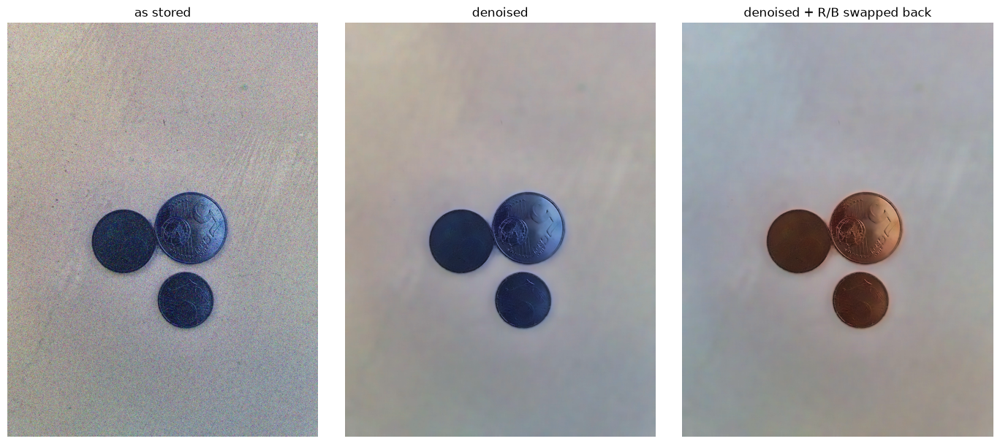

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 6))
raw = cv2.imread(os.path.join(TGT_DIR, 'image_1.jpg'))
den = cv2.fastNlMeansDenoisingColored(raw, None, 17, 17, 7, 21)

for ax, im, title in zip(axes, [raw, den, den[:, :, ::-1]],
                         ['as stored', 'denoised', 'denoised + R/B swapped back']):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()

### 3.3 Verifying the correction against a known coin

The argument above is visual, so it is worth one objective test. In `image_44` the lower coin is
identifiable by eye: the digit and the bimetallic structure make it a 2 euro coin, whose outer
ring is silver (cupronickel) and whose core is gold-coloured (nickel brass). The core must
therefore be **warmer** than the ring. Measuring the red-minus-blue difference in the two regions
decides the question without relying on how the image looks on screen.

In [5]:
_raw44 = cv2.imread(os.path.join(TGT_DIR, 'image_44.jpg'))
_den44 = cv2.fastNlMeansDenoisingColored(_raw44, None, 17, 17, 7, 21)

_x, _y, _R = 384.5, 739.5, 103.3                     # the 2 euro coin, located by hand
_H, _W = _den44.shape[:2]
_Y, _X = np.ogrid[:_H, :_W]
_d = np.sqrt((_X - _x) ** 2 + (_Y - _y) ** 2)
_core, _ring = _d < 0.5 * _R, (_d > 0.72 * _R) & (_d < 0.93 * _R)

for _label, _im in [('as stored', _den44), ('R/B swapped back', _den44[:, :, ::-1])]:
    _c, _r = _im[_core].mean(0), _im[_ring].mean(0)
    print(f'{_label:20} core R-B = {_c[2]-_c[0]:+7.1f}   ring R-B = {_r[2]-_r[0]:+7.1f}'
          f'   core warmer: {(_c[2]-_c[0]) > (_r[2]-_r[0])}')
print('\nA 2 euro coin has a gold core and a silver ring, so the core must be the warmer of the two.')

as stored            core R-B =   -68.8   ring R-B =   -45.7   core warmer: False
R/B swapped back     core R-B =   +68.8   ring R-B =   +45.7   core warmer: True

A 2 euro coin has a gold core and a silver ring, so the core must be the warmer of the two.


The swapped version puts the core clearly warmer than the ring, as a 2 euro coin requires; the
stored version makes both strongly blue, which no euro coin is. The correction is confirmed.

Note that even after the correction the silver ring does not come out neutral but slightly warm,
so a residual illuminant cast remains. Colour should therefore be used **relatively** — comparing
regions within one image — rather than through absolute thresholds. This matters for the
classification stage, not for detection, which uses luminance only.

---
## 4. Preprocessing

**Filter choice.** The noise is Gaussian-like and spatially uncorrelated, so a median filter is
the wrong tool: it targets impulse noise and cannot synthesise new intensities. A Gaussian filter
would suppress it but blurs the coin rims, which are exactly the structure the detector relies on.
Non-Local Means averages over *similar patches* rather than over spatially near pixels, which
preserves edges and repeated texture, and it is the filter the course material demonstrates on
Gaussian noise of σ = 20 — close to the σ ≈ 17 measured here.

**Parameter choice.** Filter strength is set to `h = 17`, of the order of the noise. Section 10
reports the check that this value neither leaves the coins noisy nor smooths away their engraving.

**Cache integrity.** Preprocessing is slow, so results are cached; but a cache that is silently
reused after the parameters change produces wrong results with no error message. This cost the
project several hours during development. The parameters are therefore recorded alongside the
cache and the cache is rebuilt automatically when they do not match.

In [6]:
NLM_H = 17           # ~ sigma of the noise
NLM_TEMPLATE = 7     # patch size
NLM_SEARCH = 21      # search window


def preprocess(bgr_as_stored):
    """Denoise with Non-Local Means and undo the red/blue channel swap.

    OpenCV reads a file into BGR order; since the file itself has R and B exchanged, imread
    already yields the channels in true-RGB order, so reversing them restores true BGR.
    """
    den = cv2.fastNlMeansDenoisingColored(bgr_as_stored, None, NLM_H, NLM_H,
                                          NLM_TEMPLATE, NLM_SEARCH)
    return den[:, :, ::-1].copy()


def _cache_signature():
    return json.dumps({'h': NLM_H, 'template': NLM_TEMPLATE, 'search': NLM_SEARCH,
                       'swap': True, 'cv2': cv2.__version__}, sort_keys=True)


def build_cache(force=False):
    """Rebuilds whenever the stored signature differs from the current parameters."""
    os.makedirs(CACHE_DIR, exist_ok=True)
    stamp = os.path.join(CACHE_DIR, 'params.json')
    current = _cache_signature()
    stale = force or not os.path.exists(stamp) or open(stamp).read() != current
    if stale:
        for f in glob.glob(os.path.join(CACHE_DIR, '*.png')):
            os.remove(f)
        print('cache parameters changed or missing: rebuilding from scratch')

    t0 = time.time()
    for i in range(1, N_IMAGES + 1):
        out = os.path.join(CACHE_DIR, f'image_{i}.png')
        if os.path.exists(out):
            continue
        cv2.imwrite(out, preprocess(cv2.imread(os.path.join(TGT_DIR, f'image_{i}.jpg'))))
    open(stamp, 'w').write(current)
    n = len(glob.glob(os.path.join(CACHE_DIR, '*.png')))
    print(f'cache ready: {n} images ({time.time()-t0:.0f}s)')


def load_target(idx):
    return cv2.imread(os.path.join(CACHE_DIR, f'image_{idx}.png'))


build_cache()

cache ready: 142 images (0s)


---
## 5. Candidate circles

Detection is organised as *propose and verify*: propose generously, then score. This decouples
recall from precision and makes a permissive proposer harmless, provided the verifier is strict.

After denoising, the luminance channel is clean enough for the gradient-based Hough transform for
circles. It is run with four parameter sets rather than one, because a single accumulator
threshold cannot serve both a high-contrast coin on paper and a faint one on concrete. The union
is then deduplicated, since the four runs return near-identical circles for the same coin.

In [7]:
MIN_RADIUS, MAX_RADIUS = 28, 160

# dp, param1 (Canny high threshold), param2 (accumulator threshold), minDist
HOUGH_PARAMS = [(1.2, 100, 30, 40), (1.5, 60, 45, 40), (1.0, 120, 25, 40), (1.2, 80, 35, 40)]


def candidates(gray):
    proposals = []
    for dp, p1, p2, min_dist in HOUGH_PARAMS:
        found = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=dp, minDist=min_dist,
                                 param1=p1, param2=p2,
                                 minRadius=MIN_RADIUS, maxRadius=MAX_RADIUS)
        if found is not None:
            proposals.extend(found[0].tolist())

    seen, unique = set(), []
    for x, y, r in proposals:
        key = (int(x / 5), int(y / 5), int(r / 4))
        if key in seen:
            continue
        seen.add(key)
        unique.append((float(x), float(y), float(r)))
    return unique

---
## 6. Scoring a candidate

A true coin rim has a specific signature: along the whole circumference the gradient is both
**strong** and **oriented along the radius**. A candidate is scored on exactly those two
quantities, sampled at 180 points around the circle:

* the fraction of sample points whose radial derivative exceeds the image's gradient threshold —
  how much of the rim is actually present;
* the mean ratio between the radial derivative and the full gradient magnitude — how well the
  edge is aligned with the circle, which rejects candidates straddling unrelated structure.

Each channel is smoothed with a Gaussian (σ = 1.6) before differentiation, the standard
precaution of differentiating a smoothed signal. The gradient threshold is derived per image from
the gradient distribution itself, because edge strength is scene dependent: concrete, cloth and
paper are not comparable.

The radius is refined by ±4 px around the proposal, keeping the best-scoring value, because the
Hough accumulator is quantised and typically lands a few pixels off.

In [8]:
GRAD_SIGMA = 1.6
N_SAMPLES = 180
RADIUS_REFINE = np.arange(-4, 4.5, 1.0)


def prepare(idx):
    """Load a preprocessed image and compute its luminance gradient field."""
    img = load_target(idx)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    sm = cv2.GaussianBlur(gray, (0, 0), GRAD_SIGMA)
    gx = cv2.Sobel(sm, cv2.CV_32F, 1, 0, 3)
    gy = cv2.Sobel(sm, cv2.CV_32F, 0, 1, 3)
    magnitude = np.hypot(gx, gy)
    threshold = max(5.0, float(np.percentile(magnitude, 88)))
    return img, gray, gx, gy, magnitude, threshold


def score_candidate(gx, gy, magnitude, threshold, x, y, r, H, W):
    theta = np.linspace(0, 2 * np.pi, N_SAMPLES, endpoint=False)
    cx, cy = np.cos(theta), np.sin(theta)

    best_score, best_r = -1.0, r
    for dr in RADIUS_REFINE:
        rr = r + dr
        px = np.clip((x + rr * cx).astype(int), 0, W - 1)
        py = np.clip((y + rr * cy).astype(int), 0, H - 1)
        radial = np.abs(gx[py, px] * cx + gy[py, px] * cy)   # derivative along the radius
        completeness = np.mean(radial > threshold)
        alignment = np.mean(radial / (magnitude[py, px] + 1e-6))
        s = 0.65 * completeness + 0.35 * alignment
        if s > best_score:
            best_score, best_r = float(s), float(rr)
    return best_score, best_r


def score_image(idx, min_score=0.30):
    """All surviving scored candidates for one image: (score, x, y, r)."""
    img, gray, gx, gy, magnitude, threshold = prepare(idx)
    H, W = gray.shape
    rows = []
    for x, y, r in candidates(gray):
        s, rr = score_candidate(gx, gy, magnitude, threshold, x, y, r, H, W)
        if s >= min_score:
            rows.append([s, float(x), float(y), rr])
    return rows

---
## 7. Selection

Scored candidates are reduced to a final set by two rules.

**Duplicate suppression.** Overlap is measured as intersection-over-union between discs rather
than by distance between centres, so that a large and a small concentric proposal are recognised
as competing while two genuinely touching coins are not.

**Physical radius band.** All coins in one photograph lie on roughly the same plane at roughly the
same distance, so their apparent diameters cannot differ by more than the ratio between the
largest and smallest euro coin, 1.585, plus a small tolerance for perspective and for the error on
the estimated radius. The band is anchored on the **largest** accepted circle and only circles too
small to be coins are removed.

Anchoring on the highest-scoring circle instead is tempting but fragile: small high-contrast
specks of background have very complete rims and can outscore a real coin, and a band built around
one of them excludes the coins themselves. The largest circle is the safer reference on this data,
where every false positive is smaller than the coins; it would need revisiting on scenes
containing large circular distractors such as plates or lids.

In [9]:
SCORE_MIN     = 0.64
IOU_MAX       = 0.10
RADIUS_MARGIN = 1.12


def circle_iou(x1, y1, r1, x2, y2, r2):
    d = np.hypot(x1 - x2, y1 - y2)
    if d >= r1 + r2:
        return 0.0
    if d <= abs(r1 - r2):                      # one disc inside the other
        return min(r1, r2) ** 2 / max(r1, r2) ** 2
    a1 = np.arccos(np.clip((d * d + r1 * r1 - r2 * r2) / (2 * d * r1), -1, 1))
    a2 = np.arccos(np.clip((d * d + r2 * r2 - r1 * r1) / (2 * d * r2), -1, 1))
    inter = r1 * r1 * (a1 - np.sin(2 * a1) / 2) + r2 * r2 * (a2 - np.sin(2 * a2) / 2)
    return inter / (np.pi * (r1 * r1 + r2 * r2) - inter)


def select(rows, score_min=SCORE_MIN, iou_max=IOU_MAX, radius_margin=RADIUS_MARGIN):
    ranked = sorted([r for r in rows if r[0] >= score_min], key=lambda r: -r[0])

    kept = []
    for s, x, y, r in ranked:
        if all(circle_iou(x, y, r, X, Y, R) < iou_max for _, X, Y, R in kept):
            kept.append([s, x, y, r])
    if not kept:
        return kept

    r_max = max(k[3] for k in kept)
    return [k for k in kept if k[3] >= r_max / (MAX_DIAMETER_RATIO * radius_margin)]

---
## 8. Results

In [10]:
import os
if os.path.exists(CAND_FILE):
    os.remove(CAND_FILE)
print('candidates.json rimosso, verrà ricalcolato')

candidates.json rimosso, verrà ricalcolato


In [11]:
if os.path.exists(CAND_FILE):
    all_candidates = {int(k): v for k, v in json.load(open(CAND_FILE)).items()}
else:
    all_candidates, t0 = {}, time.time()
    for i in range(1, N_IMAGES + 1):
        all_candidates[i] = score_image(i)
        if i % 25 == 0:
            print(f'  {i}/{N_IMAGES}  ({time.time()-t0:.0f}s)', flush=True)
    json.dump({str(k): v for k, v in all_candidates.items()}, open(CAND_FILE, 'w'))

print('median candidates per image:',
      int(np.median([len(v) for v in all_candidates.values()])))

  25/142  (6s)
  50/142  (41s)
  75/142  (46s)
  100/142  (55s)
  125/142  (79s)
median candidates per image: 20


In [12]:
detections = {i: select(all_candidates[i]) for i in range(1, N_IMAGES + 1)}

exact = sum(len(detections[i]) == GROUND_TRUTH[i] for i in range(1, N_IMAGES + 1))
abs_err = sum(abs(len(detections[i]) - GROUND_TRUTH[i]) for i in range(1, N_IMAGES + 1))

print(f'images with exact count  : {exact}/{N_IMAGES}  ({exact/N_IMAGES:.1%})')
print(f'mean absolute count error: {abs_err/N_IMAGES:.3f}')
print(f'coins detected           : {sum(len(d) for d in detections.values())}'
      f'   (annotated: {sum(GROUND_TRUTH.values())})')

wrong = [(i, GROUND_TRUTH[i], len(detections[i]))
         for i in range(1, N_IMAGES + 1) if len(detections[i]) != GROUND_TRUTH[i]]
print('\nmismatches (image, annotated, detected):', wrong)
print('missed:', sum(max(0, g - d) for _, g, d in wrong),
      ' spurious:', sum(max(0, d - g) for _, g, d in wrong))

images with exact count  : 136/142  (95.8%)
mean absolute count error: 0.056
coins detected           : 324   (annotated: 328)

mismatches (image, annotated, detected): [(43, 2, 1), (44, 2, 1), (55, 2, 1), (85, 5, 2), (96, 8, 9), (98, 4, 5)]
missed: 6  spurious: 2


### 8.1 Sensitivity of the thresholds

Three thresholds were tuned on the same images used for evaluation, so the result is only
meaningful if the optimum is a region rather than a point.

In [13]:
print(f'{"score_min":>10}{"iou_max":>9}{"margin":>8}{"exact":>7}{"MAE":>8}')
for sm in [0.56, 0.60, 0.64, 0.68]:
    for iou in [0.10, 0.15, 0.20]:
        for mg in [1.12, 1.20]:
            d = {i: select(all_candidates[i], sm, iou, mg) for i in range(1, N_IMAGES + 1)}
            e = sum(len(d[i]) == GROUND_TRUTH[i] for i in range(1, N_IMAGES + 1))
            a = sum(abs(len(d[i]) - GROUND_TRUTH[i]) for i in range(1, N_IMAGES + 1))
            print(f'{sm:10.2f}{iou:9.2f}{mg:8.2f}{e:7d}{a/N_IMAGES:8.3f}')

 score_min  iou_max  margin  exact     MAE
      0.56     0.10    1.12    135   0.063
      0.56     0.10    1.20    135   0.063
      0.56     0.15    1.12    132   0.085
      0.56     0.15    1.20    131   0.092
      0.56     0.20    1.12    126   0.162
      0.56     0.20    1.20    124   0.155
      0.60     0.10    1.12    135   0.063
      0.60     0.10    1.20    135   0.063
      0.60     0.15    1.12    133   0.077
      0.60     0.15    1.20    132   0.085
      0.60     0.20    1.12    129   0.113
      0.60     0.20    1.20    128   0.120
      0.64     0.10    1.12    136   0.056
      0.64     0.10    1.20    135   0.056
      0.64     0.15    1.12    134   0.070
      0.64     0.15    1.20    132   0.077
      0.64     0.20    1.12    130   0.099
      0.64     0.20    1.20    128   0.106
      0.68     0.10    1.12    135   0.063
      0.68     0.10    1.20    135   0.056
      0.68     0.15    1.12    135   0.063
      0.68     0.15    1.20    134   0.063
      0.68 

### 8.2 What was tried and removed

Three further mechanisms were implemented, measured under the same protocol as above — each
variant's thresholds re-tuned over the same grid — and then removed. The figures are counts of
images whose number of coins is recovered exactly, out of 142.

| variant | exact | MAE |
|---|---|---|
| chroma blob proposals + colour gradient + relative gate | 137 | 0.035 |
| colour gradient + relative gate, no blob proposals | **138** | **0.028** |
| blob proposals + relative gate, luminance gradient | 136 | 0.042 |
| relative gate only, luminance gradient | 136 | 0.042 |
| **this notebook** — none of the three | 135 | 0.049 |

**Chroma blob proposals.** Coins that are nearly isoluminant with their background are invisible
in the luminance channel, so a second proposer thresholded the CIELAB chroma channels with Otsu
and kept the connected components that were round enough. Measured, it *lowers* accuracy: the
proposals it adds are worth less than the false positives they bring. Removing it also removes
automatic thresholding, morphological operators and connected-component labelling, none of which
belong to the course material.

**Colour gradient.** The gradient was computed jointly over the three CIELAB channels through Di
Zenzo's structure tensor, whose largest eigenvalue is the strongest colour change at a pixel — the
Harris matrix of the course generalised to three channels. It is worth two images out of 142. It
was dropped to keep the pipeline within one colour space and one gradient definition.

**Relative score gate.** Candidates scoring below 70% of the best detection *in the same image*
were discarded, on the argument that a spurious circle in the gap between two touching coins has
no continuous rim and scores far below a real one. Worth one image out of 142. It was dropped
because it is the only rule in the pipeline justified statistically rather than physically, and
because its value proved sensitive to the exact threshold.

The retained configuration is therefore three images worse than the best one measured. That is a
deliberate choice: the three mechanisms cost two extra colour spaces, four operators outside the
course material and three additional thresholds, for 2.1% of accuracy on the counting metric.

A note on how these figures were obtained. An earlier round of this analysis reached the opposite
conclusion on all three points. Its numbers came from a preprocessing cache built with different
parameters and silently reused — the failure the cache signature in section 4 now prevents. The
table above was recomputed after that was found.

### 8.3 Qualitative check

The count-based score cannot reveal errors that cancel out, nor whether a circle is well centred
on the coin — which matters, because these circles become the crops handed to classification.

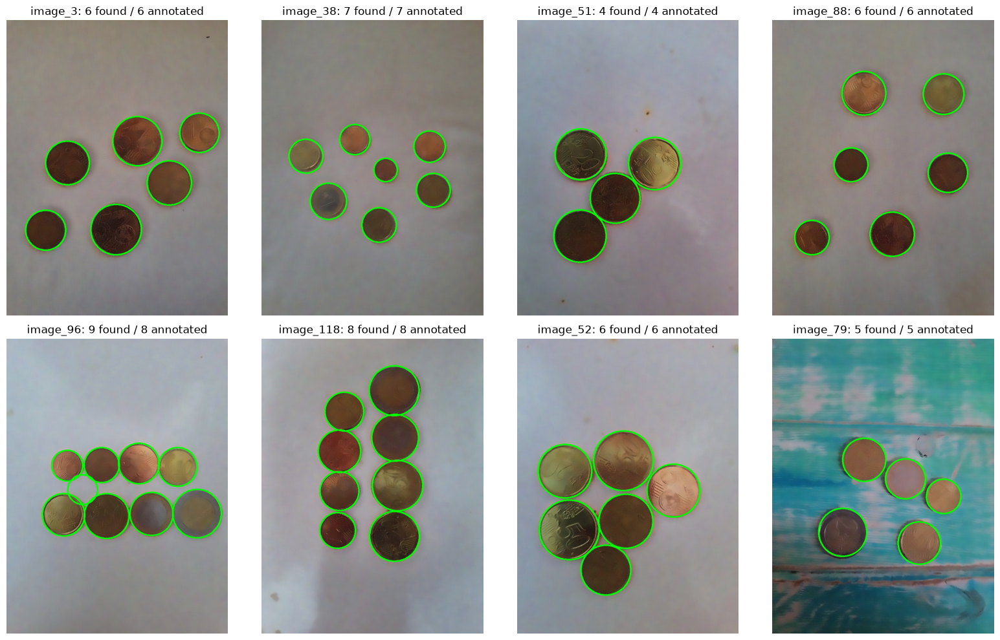

In [14]:
def show_detections(indices, cols=4):
    rows = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 5 * rows))
    for ax, idx in zip(np.ravel(axes), indices):
        im = load_target(idx).copy()
        for s, x, y, r in detections[idx]:
            cv2.circle(im, (int(x), int(y)), int(r), (0, 255, 0), 4)
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(f'image_{idx}: {len(detections[idx])} found / {GROUND_TRUTH[idx]} annotated')
        ax.axis('off')
    for ax in np.ravel(axes)[len(indices):]:
        ax.axis('off')
    plt.tight_layout(); plt.show()


show_detections([3, 38, 51, 88, 96, 118, 52, 79])

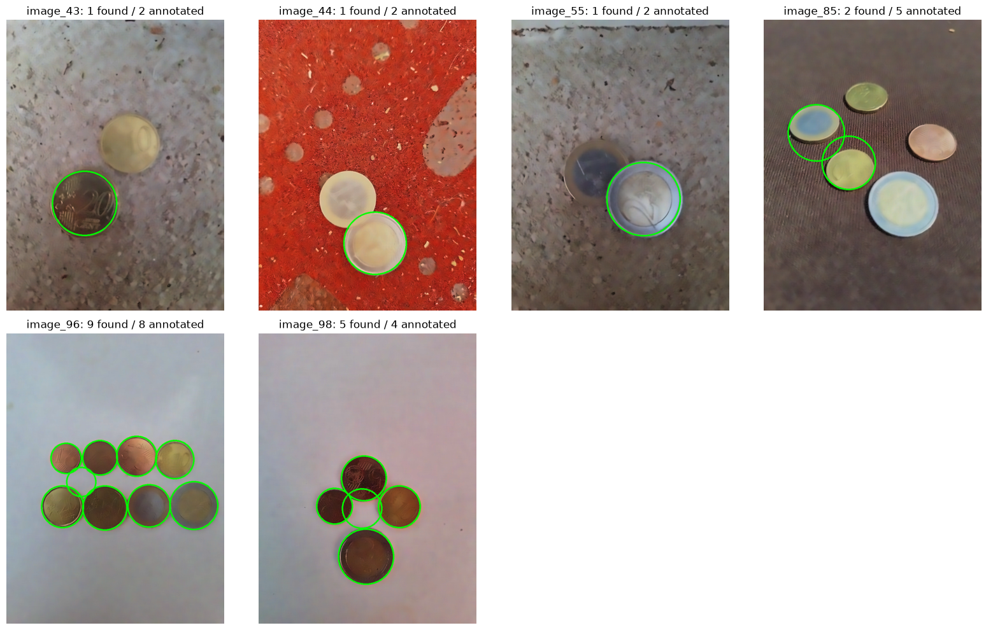

In [15]:
show_detections([i for i, _, _ in wrong])

---
## 9. Inspecting a single image

The cell below runs the pipeline on one image from the file on disk rather than from the cached
candidates, and lays out the four stages side by side. The third panel is the useful one when
something goes wrong: each candidate is drawn in the colour of the stage that discarded it and
labelled with it, so a coin that was never proposed, one whose rim scored too low, one suppressed
as a duplicate and one outside the physical size band are four different faults with four
different fixes. Candidates rejected for low support are the large majority and are drawn thin
and unlabelled to keep the panel readable.

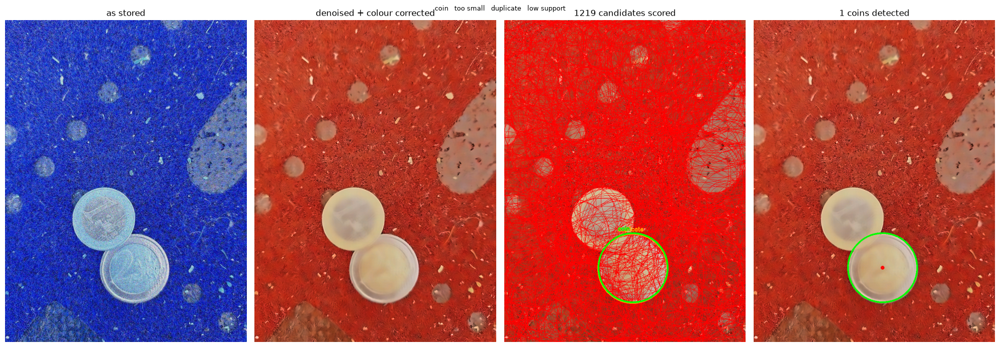

image_44: 1 detected, 2 annotated
candidates by outcome: {'coin': 1, 'duplicate': 1, 'low support': 1217}
  1: score 0.864  centre (385, 739)  radius 103.2


In [16]:
TEST_IMAGE = 44          # <- change this

STAGE_COLOURS = {'coin': (0, 255, 0), 'too small': (255, 0, 255),
                 'duplicate': (0, 165, 255), 'low support': (0, 0, 255)}


def select_with_stages(rows):
    """select(), instrumented: also returns which stage discarded each candidate."""
    stage = {}
    key_of = lambda x, y, r: (round(x, 1), round(y, 1), round(r, 1))

    kept = []
    for s, x, y, r in sorted(rows, key=lambda r: -r[0]):
        k = key_of(x, y, r)
        if s < SCORE_MIN:
            stage[k] = 'low support'
        elif any(circle_iou(x, y, r, X, Y, R) >= IOU_MAX for _, X, Y, R in kept):
            stage[k] = 'duplicate'
        else:
            kept.append([s, x, y, r]); stage[k] = 'coin'

    if kept:
        limit = max(k[3] for k in kept) / (MAX_DIAMETER_RATIO * RADIUS_MARGIN)
        survivors = []
        for k in kept:
            if k[3] < limit:
                stage[key_of(k[1], k[2], k[3])] = 'too small'
            else:
                survivors.append(k)
        kept = survivors
    return kept, stage


def inspect_image(idx):
    raw = cv2.imread(os.path.join(TGT_DIR, f'image_{idx}.jpg'))
    prepared = load_target(idx)
    scored = score_image(idx, min_score=0.0)
    final, stage = select_with_stages(scored)

    candidate_vis = prepared.copy()
    for s, x, y, r in sorted(scored, key=lambda r: r[0]):
        label = stage.get((round(x, 1), round(y, 1), round(r, 1)), 'low support')
        colour = STAGE_COLOURS[label]
        if label == 'low support':
            cv2.circle(candidate_vis, (int(x), int(y)), int(r), colour, 1)
            continue
        cv2.circle(candidate_vis, (int(x), int(y)), int(r), colour, 3)
        cv2.putText(candidate_vis, label, (int(x) - 45, max(16, int(y - r) - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, colour, 2)

    final_vis = prepared.copy()
    for s, x, y, r in final:
        cv2.circle(final_vis, (int(x), int(y)), int(r), (0, 255, 0), 4)
        cv2.circle(final_vis, (int(x), int(y)), 3, (0, 0, 255), 4)

    panels = [(raw, 'as stored'), (prepared, 'denoised + colour corrected'),
              (candidate_vis, f'{len(scored)} candidates scored'),
              (final_vis, f'{len(final)} coins detected')]
    fig, axes = plt.subplots(1, 4, figsize=(20, 7))
    for ax, (im, title) in zip(axes, panels):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(title); ax.axis('off')
    plt.suptitle('   '.join(STAGE_COLOURS), fontsize=9)
    plt.tight_layout(); plt.show()

    from collections import Counter
    print(f'image_{idx}: {len(final)} detected, {GROUND_TRUTH.get(idx)} annotated')
    print('candidates by outcome:', dict(Counter(stage.values())))
    for n, (s, x, y, r) in enumerate(sorted(final, key=lambda k: -k[0]), 1):
        print(f'  {n}: score {s:.3f}  centre ({x:.0f}, {y:.0f})  radius {r:.1f}')


inspect_image(TEST_IMAGE)

---
## 10. Was the denoising strength right?

`NLM_H` controls a trade-off: too little and the gradient field stays noisy, too much and the
engraving on the coins is smoothed away — and the engraving is what a classification stage would
have to read. The global noise estimate cannot arbitrate, because it cannot separate noise from
texture: on a densely woven background it reads high whatever the filter does.

The measurement below separates the two regions. Inside the coin discs the reading should stay
close to that of the clean reference coins, whose entire response is engraving; over the
background it should fall close to zero, since the backgrounds are smooth surfaces.

In [17]:
inside, outside = [], []
for i in range(1, N_IMAGES + 1):
    if len(detections[i]) != GROUND_TRUTH[i] or not detections[i]:
        continue
    gray = cv2.cvtColor(load_target(i), cv2.COLOR_BGR2GRAY)
    H, W = gray.shape
    Y, X = np.ogrid[:H, :W]
    mask = np.zeros((H, W), bool)
    for s, x, y, r in detections[i]:
        mask |= ((X - x) ** 2 + (Y - y) ** 2) < (0.80 * r) ** 2
    if mask.sum() < 500 or (~mask).sum() < 500:
        continue
    inside.append(estimate_noise_sigma(gray, mask))
    outside.append(estimate_noise_sigma(gray, ~mask))

reference = []
for name in COIN_MM:
    b = cv2.imread(os.path.join(REF_DIR, name + '.jpg'), cv2.IMREAD_GRAYSCALE)
    c = cv2.HoughCircles(b, cv2.HOUGH_GRADIENT, dp=1.2, minDist=200, param1=100,
                         param2=45, minRadius=40, maxRadius=250)
    if c is None:
        continue
    x, y, r = c[0][0]
    H, W = b.shape
    Y, X = np.ogrid[:H, :W]
    reference.append(estimate_noise_sigma(b, ((X - x) ** 2 + (Y - y) ** 2) < (0.80 * r) ** 2))

print(f'inside detected coins : median {np.median(inside):5.2f}')
print(f'over the background   : median {np.median(outside):5.2f}')
print(f'inside clean reference coins (all engraving, no noise): median {np.median(reference):5.2f}')

inside detected coins : median  2.04
over the background   : median  0.61
inside clean reference coins (all engraving, no noise): median  4.00


The background reading falls close to zero, so the noise is effectively removed. Inside the coins
the reading sits well above zero but below the clean reference coins, which is the expected
outcome: what survives there is engraving, partly attenuated. Raising `NLM_H` would push that
figure down — that is, it would erase engraving, not noise.

This also explains a misreading made during development. `image_44` is photographed on a densely
woven red fabric, and its global estimate stays around 6 whatever the filter strength. Taken as a
diagnostic for the whole pipeline it suggested the denoising was failing, which it was not.

---
## 11. Limitations

**The metric measures counting, not localisation.** The annotation records how many coins are in
each image, not where they are. Circle placement has only been assessed by eye. This is the main
open item, and it matters for what comes next: classifying by size has to resolve diameter gaps of
4.5% (1 euro against 20 cent) and 7.6% (5 cent against 10 cent), so the accuracy of the estimated
radius is the error budget of that stage.

**No held-out split.** Three thresholds were fitted on the same 142 images used to report the
result, so the figure describes this set rather than predicting performance on new photographs.
The sensitivity table of section 8.1 is the only evidence against over-fitting.

**Errors are close to balanced, but not exactly.** The residual failures split into a few coins
missed and a few spurious detections, leaving the total slightly under the annotated count. For a
monetary total this partial cancellation is luck rather than design: the two error types are
independent, and nothing in the pipeline keeps them in balance.

**The physical radius band assumes the largest circle is a coin.** It holds on this dataset, where
every false positive is smaller than the coins, and would need revisiting on scenes with large
circular distractors.

---
# Part 2 — Classification

Each detected coin is assigned a denomination in two steps:

1. **Colour** decides the metal: bimetallic coins are resolved directly into 1 € or 2 €, the others
   are narrowed to the copper family (1, 2, 5 cent) or the Nordic-gold family (10, 20, 50 cent).
2. **Shape-based matching** (L5) chooses the denomination inside the family, by comparing the
   engraving of the coin with the reference models.

Both steps use only the circle found in Part 1 (centre and radius). The reference images are only
cropped and rescaled, never altered.

### Two denoising levels

Detection and classification need opposite things from the image. Detection needs clean rims, and
strong Non-Local Means denoising (`h = 17`) provides them. Classification needs the engraving, and
section 10 shows that the same filter halves it (2.04 inside the coins against 4.00 on the clean
references). For that reason the classification crops are taken from the **original file**, with the
red/blue channels restored but **without** NLM. Noise is instead reduced by rescaling the coin to a
fixed size (which averages pixels) and by a light Gaussian before differentiation.

Measured on the hand-labelled single coins of section 15, the shape matching of section 13 improves
monotonically as the NLM strength on the crop is lowered:

| NLM `h` on the crop | 17 | 13 | 9 | 5 | 0 |
|---|---|---|---|---|---|
| correct / 14 | 6 | 6 | 7 | 8 | 8 |

Colour, on the contrary, is measured on the denoised image of Part 1: it averages over whole regions,
so it benefits from the removal of noise and loses nothing from the loss of engraving.

---
## 12.0 Refining the circles before classifying

Counting only needs to know *that* a coin is there; classification measures regions at precise
distances from the centre, so it also needs the circle to sit exactly on the coin. Two refinements
are applied to the final detections of Part 1. They do not touch `candidates.json`.

**Centre refinement.** Section 7 refines the radius (±4 px) but keeps the centre proposed by Hough,
which works on a coarse accumulator (`dp` up to 1.5) and is pulled by shadows and touching coins.
In `image_27` the circles were off by 4–9 px: part of the "ring" region fell on the blue background,
a copper coin was read as a 2 € coin and a 1 € coin as copper. Here the same rim score of section 7
is maximised over shifts of the centre up to ±12 px (2 px steps, then 1 px). Over the dataset the
median shift is 2 px, 65 of 324 circles move by more than 4 px, and the mean rim score rises from
0.966 to 0.979.

**Rejecting circles that are only surface.** A coin must differ from the surface it lies on
*somewhere*: a copper, gold or 2 € core differs in colour, and a 1 € coin — whose silver core can
look exactly like a light surface — has a gold ring. For each circle, core and ring are compared with
the **free surface of the whole image** (the pixels outside every detected circle; the annulus around
the coin would fall on neighbouring coins in crowded images), in log-luminance and chromaticity. A
circle is rejected when *neither* region differs. Across the dataset the lowest value is 0.105, the
circle found in the gap between four coins of `image_96`, and the next is 0.156, a real coin; the
threshold sits in between. With a single negative example the threshold is only weakly supported,
but the rule removes that circle and nothing else.

In [18]:
CENTRE_SHIFTS = np.arange(-12, 13, 2)
SURFACE_MIN = 0.13


def refine_centre(gx, gy, magnitude, threshold, x, y, r, H, W):
    """Coarse-to-fine search of the centre that maximises the rim score of section 7."""
    best = (score_candidate(gx, gy, magnitude, threshold, x, y, r, H, W)[0], x, y, r)
    for dx in CENTRE_SHIFTS:
        for dy in CENTRE_SHIFTS:
            s, rr = score_candidate(gx, gy, magnitude, threshold, x + dx, y + dy, r, H, W)
            if s > best[0]:
                best = (s, x + dx, y + dy, rr)
    _, bx, by, br = best
    for dx in (-1, 0, 1):
        for dy in (-1, 0, 1):
            s, rr = score_candidate(gx, gy, magnitude, threshold, bx + dx, by + dy, br, H, W)
            if s > best[0]:
                best = (s, bx + dx, by + dy, rr)
    return best


def surface_distance(img, dets):
    """For each circle: how much core and ring differ from the free surface of the image
    (the larger of the two)."""
    f = img.astype(np.float32)
    H, W = f.shape[:2]
    Y, X = np.ogrid[:H, :W]
    free = np.ones((H, W), bool)
    for s, x, y, r in dets:
        free &= (X - x) ** 2 + (Y - y) ** 2 > (1.15 * r) ** 2
    surface = np.median(f[free], axis=0)

    def dist(v):
        (B, G, R), (Bs, Gs, Rs) = v, surface
        lum = (R + G + B) / (Rs + Gs + Bs)
        chroma = np.hypot((R - B) / (R + G + B) - (Rs - Bs) / (Rs + Gs + Bs),
                          (R - G) / (R + G + B) - (Rs - Gs) / (Rs + Gs + Bs))
        return float(np.hypot(0.5 * np.log(lum), chroma))

    out = []
    for s, x, y, r in dets:
        d2 = (X - x) ** 2 + (Y - y) ** 2
        core = f[d2 < (0.55 * r) ** 2].mean(0)
        ring = f[(d2 > (0.78 * r) ** 2) & (d2 < (0.92 * r) ** 2)].mean(0)
        out.append(max(dist(core), dist(ring)))
    return out


detections_part1 = detections
detections, t0, removed, shifts = {}, time.time(), [], []
for i in range(1, N_IMAGES + 1):
    img, gray, gx, gy, magnitude, threshold = prepare(i)
    H, W = gray.shape
    refined = []
    for s, x, y, r in detections_part1[i]:
        _, nx, ny, nr = refine_centre(gx, gy, magnitude, threshold, x, y, r, H, W)
        refined.append([s, nx, ny, nr])
        shifts.append(np.hypot(nx - x, ny - y))
    dist = surface_distance(img, refined)
    detections[i] = [d for d, v in zip(refined, dist) if v >= SURFACE_MIN]
    removed += [(i, round(v, 3)) for v in dist if v < SURFACE_MIN]

shifts = np.array(shifts)
print(f'refined in {time.time() - t0:.0f}s')
print(f'centre shift: median {np.median(shifts):.1f} px, > 4 px: {(shifts > 4).sum()}, max {shifts.max():.1f} px')
print(f'circles rejected as bare surface: {removed}')
exact = sum(len(detections[i]) == GROUND_TRUTH[i] for i in range(1, N_IMAGES + 1))
print(f'images with exact count after refinement: {exact}/{N_IMAGES}')

refined in 67s
centre shift: median 2.0 px, > 4 px: 65, max 13.2 px
circles rejected as bare surface: [(96, 0.105)]
images with exact count after refinement: 137/142


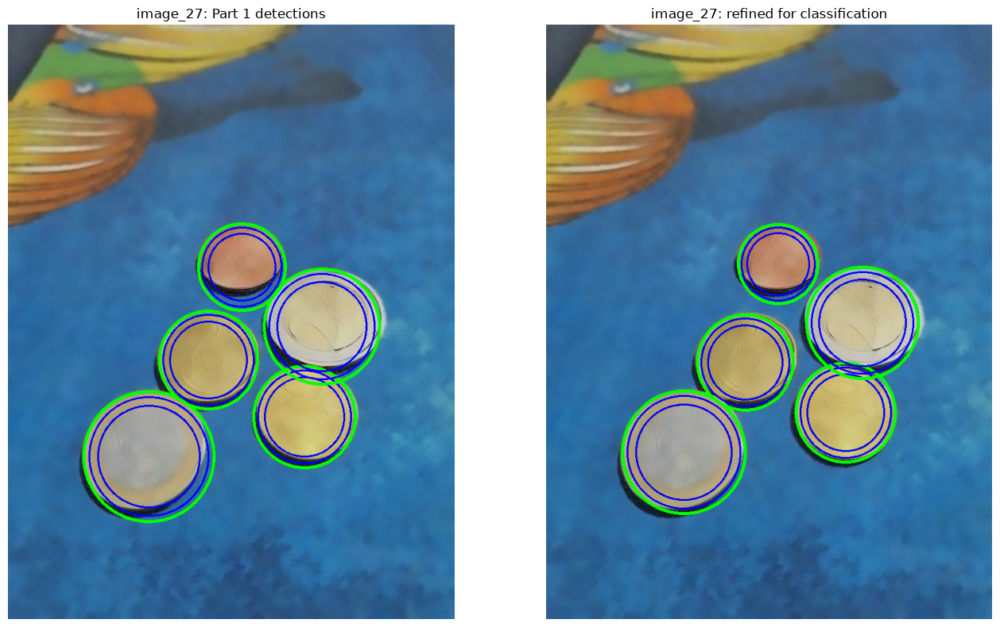

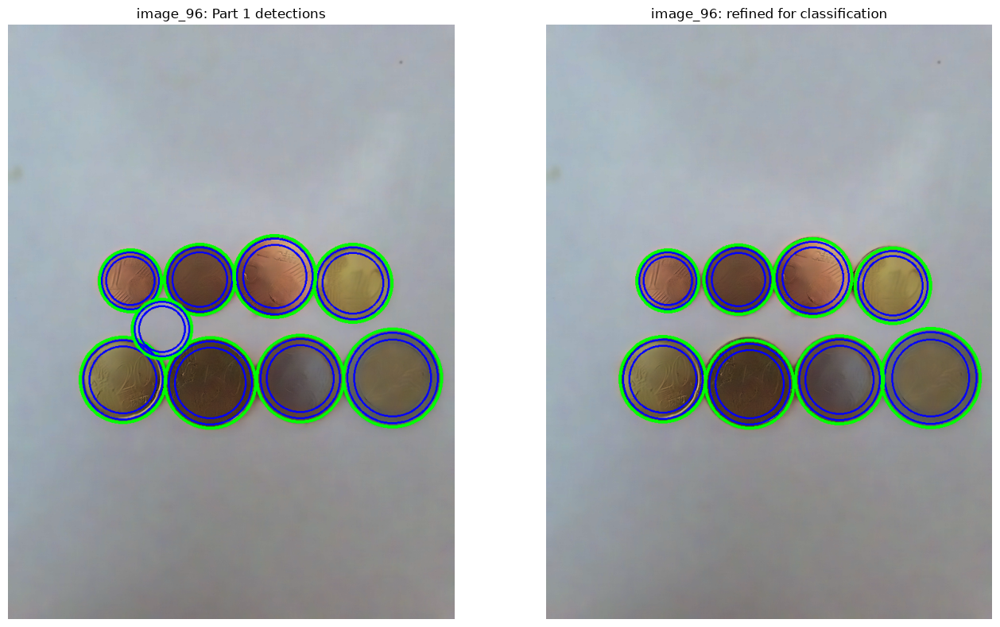

In [19]:
def show_refinement(idx):
    img = load_target(idx)
    fig, axes = plt.subplots(1, 2, figsize=(14, 8))
    for ax, (title, dets) in zip(axes, [('Part 1 detections', detections_part1[idx]),
                                        ('refined for classification', detections[idx])]):
        vis = img.copy()
        for s, x, y, r in dets:
            c = (int(round(x)), int(round(y)))
            cv2.circle(vis, c, int(r), (0, 255, 0), 3)
            cv2.circle(vis, c, int(0.78 * r), (255, 0, 0), 2)
            cv2.circle(vis, c, int(0.92 * r), (255, 0, 0), 2)
        ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax.set_title(f'image_{idx}: {title}'); ax.axis('off')
    plt.tight_layout(); plt.show()


show_refinement(27)
show_refinement(96)

---
## 12. Colour

Three regions are measured on each coin: the **core** (inside 45% of the radius), the **ring**
(between 78% and 92%) and a **background annulus** (between 1.3 and 1.9 radii). For each region two
intensity-invariant quantities are computed, so that shading and exposure cancel out:

* **warmth** $(R-B)/(R+G+B)$
* **redness** $(R-G)/(R+G+B)$

Every value is taken **relative to the background**. This cancels the colour cast of the illuminant,
which section 3.3 showed is still present after the channel correction.

The key physical fact is that **silver has no colour of its own**: cupronickel reflects the light of
the scene, so it takes the tint of the background. Nickel-brass (gold) and copper are instead clearly
warmer than the background. Hence:

* **core against ring** decides whether the coin is bimetallic. On a single-metal coin the two
  regions have the same tint; on a bimetallic coin one of them is silver and the other gold. The
  difference *core warmth − ring warmth* is therefore close to zero for one metal, clearly positive
  for a 2 € coin (gold core) and clearly negative for a 1 € coin (gold ring). Because both terms
  are measured against the same background, the background **cancels out** of the difference —
  which matters on coloured surfaces (section 12.2).
* for single-metal coins, **redness** against the background separates copper from gold.

`image_13` is a good example. As stored, its ring is blue and it looks like a 2 € coin; after the
channel correction the ring is warm (+47 in R−B against +15 for the background) and the core has
the background tint (+17): gold ring, silver core, 1 €.

In [20]:
def colour_features(img, x, y, r):
    """Warmth and redness of core and ring, relative to the background annulus."""
    f = img.astype(np.float32)
    H, W = f.shape[:2]
    Y, X = np.ogrid[:H, :W]
    d = np.sqrt((X - x) ** 2 + (Y - y) ** 2)
    regions = {'core': d < 0.45 * r,
               'ring': (d > 0.78 * r) & (d < 0.92 * r),
               'bg':   (d > 1.30 * r) & (d < 1.90 * r)}
    stats = {}
    for name, mask in regions.items():
        B, G, R = f[mask].mean(0)
        S = R + G + B + 1e-6
        stats[name] = ((R - B) / S, (R - G) / S)          # (warmth, redness)
    return {'core_warmth': stats['core'][0] - stats['bg'][0],
            'ring_warmth': stats['ring'][0] - stats['bg'][0],
            'core_redness': stats['core'][1] - stats['bg'][1]}


feats = []                       # one entry per detected coin: (image, x, y, r, features)
for i in range(1, N_IMAGES + 1):
    img = load_target(i)
    for s, x, y, r in detections[i]:
        feats.append((i, x, y, r, colour_features(img, x, y, r)))
print(f'colour features computed for {len(feats)} coins')

colour features computed for 323 coins


### 12.1 Thresholds from the data, without labels

The thresholds are read off the distributions of **all** detected coins, at the gaps between the
groups. No label is involved, so the evaluation of section 15 remains an independent check.

* **Core − ring warmth** has a large central peak (single-metal coins) centred at about **+0.02** —
  not exactly zero, because the rim is slightly shaded — and two tails: gold ring (1 €) on the left,
  gold core (2 €) on the right. The thresholds sit in the valleys on either side, at the same
  distance (0.06) from the centre of the peak: **−0.06** and **+0.08**.
* Among single-metal coins, **core redness** has a gold peak around 0.06 and a copper peak around 0.17.
  The valley between them, at 0.08–0.10, is shallow, so the threshold is **0.09** and coins inside an
  **uncertainty band 0.08–0.12** keep both families as candidates, leaving the decision to shape
  matching.


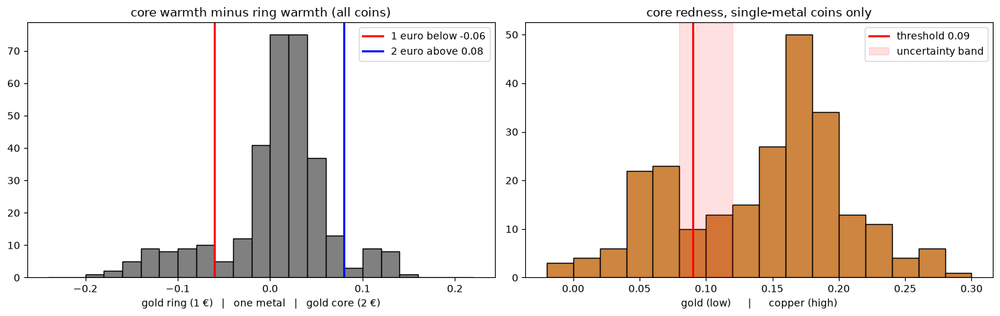

1 euro (gold ring):  44
2 euro (gold core):  21
single metal:        258
   of which inside the uncertainty band: 23


In [21]:
BIMETAL_LOW, BIMETAL_HIGH = -0.06, 0.08   # core-minus-ring warmth: below -> 1 euro, above -> 2 euro
RED_T = 0.09                    # core redness above this = copper, below = gold
RED_BAND = (0.08, 0.12)         # too close to call: keep both families

diff = np.array([f['core_warmth'] - f['ring_warmth'] for *_, f in feats])
single_metal = (diff > BIMETAL_LOW) & (diff < BIMETAL_HIGH)
redness = np.array([f['core_redness'] for *_, f in feats])[single_metal]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(diff, bins=np.arange(-0.24, 0.24, 0.02), color='grey', edgecolor='k')
axes[0].axvline(BIMETAL_LOW, color='r', lw=2, label=f'1 euro below {BIMETAL_LOW}')
axes[0].axvline(BIMETAL_HIGH, color='b', lw=2, label=f'2 euro above {BIMETAL_HIGH}')
axes[0].set_title('core warmth minus ring warmth (all coins)')
axes[0].set_xlabel('gold ring (1 €)   |   one metal   |   gold core (2 €)'); axes[0].legend()
axes[1].hist(redness, bins=np.arange(-0.02, 0.31, 0.02), color='peru', edgecolor='k')
axes[1].axvline(RED_T, color='r', lw=2, label=f'threshold {RED_T}')
axes[1].axvspan(*RED_BAND, color='r', alpha=0.12, label='uncertainty band')
axes[1].set_title('core redness, single-metal coins only')
axes[1].set_xlabel('gold (low)      |      copper (high)'); axes[1].legend()
plt.tight_layout(); plt.show()

print(f'1 euro (gold ring):  {int((diff <= BIMETAL_LOW).sum())}')
print(f'2 euro (gold core):  {int((diff >= BIMETAL_HIGH).sum())}')
print(f'single metal:        {int(single_metal.sum())}')
print(f'   of which inside the uncertainty band: '
      f'{int(((redness >= RED_BAND[0]) & (redness <= RED_BAND[1])).sum())}')

image_96
  coin 1: core warmth +0.241  ring warmth +0.195  core-ring +0.046  core redness +0.154  ->  ['1cent', '2cent', '5cent']
  coin 2: core warmth +0.125  ring warmth -0.006  core-ring +0.131  core redness +0.042  ->  ['2euro']
  coin 3: core warmth +0.186  ring warmth +0.152  core-ring +0.034  core redness +0.032  ->  ['10cent', '20cent', '50cent']
  coin 4: core warmth +0.195  ring warmth +0.173  core-ring +0.022  core redness +0.112  ->  ['1cent', '2cent', '5cent', '10cent', '20cent', '50cent']
  coin 5: core warmth +0.204  ring warmth +0.175  core-ring +0.030  core redness +0.063  ->  ['10cent', '20cent', '50cent']
  coin 6: core warmth -0.011  ring warmth +0.120  core-ring -0.131  core redness +0.005  ->  ['1euro']
  coin 7: core warmth +0.205  ring warmth +0.206  core-ring -0.002  core redness +0.107  ->  ['1cent', '2cent', '5cent', '10cent', '20cent', '50cent']
  coin 8: core warmth +0.196  ring warmth +0.175  core-ring +0.021  core redness +0.135  ->  ['1cent', '2cent', '5

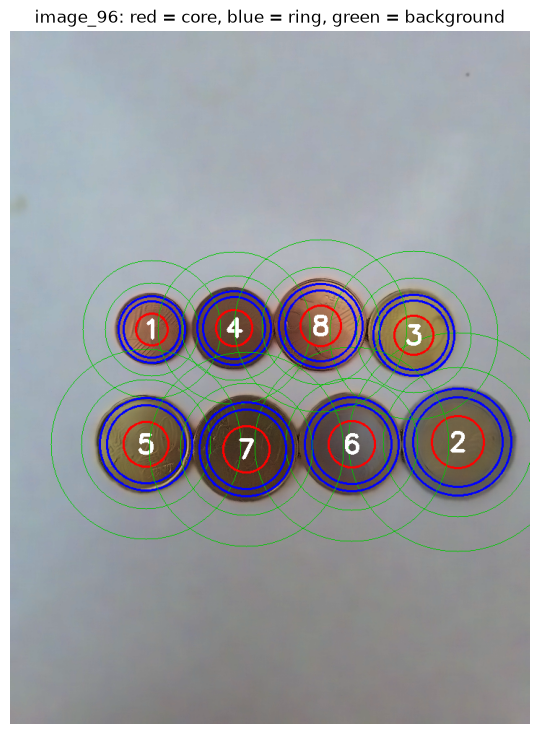

In [22]:
COPPER = ['1cent', '2cent', '5cent']
GOLD = ['10cent', '20cent', '50cent']


def colour_candidates(f):
    """Denominations compatible with the colour of the coin."""
    d = f['core_warmth'] - f['ring_warmth']          # the background cancels out here
    if d <= BIMETAL_LOW:
        return ['1euro']                             # gold ring, silver core
    if d >= BIMETAL_HIGH:
        return ['2euro']                             # gold core, silver ring
    if RED_BAND[0] <= f['core_redness'] <= RED_BAND[1]:
        return COPPER + GOLD
    return COPPER if f['core_redness'] > RED_T else GOLD


def show_colour(idx):
    """Draws the three measurement regions of every coin and prints the colour decision."""
    img = load_target(idx)
    vis = img.copy()
    print(f'image_{idx}')
    for k, (s, x, y, r) in enumerate(detections[idx], 1):
        f = colour_features(img, x, y, r)
        c = (int(x), int(y))
        cv2.circle(vis, c, int(0.45 * r), (0, 0, 255), 2)                 # core
        cv2.circle(vis, c, int(0.78 * r), (255, 0, 0), 2)                 # ring (inner edge)
        cv2.circle(vis, c, int(0.92 * r), (255, 0, 0), 2)                 # ring (outer edge)
        cv2.circle(vis, c, int(1.30 * r), (0, 200, 0), 1)                 # background annulus
        cv2.circle(vis, c, int(1.90 * r), (0, 200, 0), 1)
        cv2.putText(vis, str(k), (int(x) - 12, int(y) + 12), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 4)
        print(f'  coin {k}: core warmth {f["core_warmth"]:+.3f}  ring warmth {f["ring_warmth"]:+.3f}'
              f'  core-ring {f["core_warmth"] - f["ring_warmth"]:+.3f}  core redness {f["core_redness"]:+.3f}'
              f'  ->  {colour_candidates(f)}')
    plt.figure(figsize=(7, 9)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    plt.title(f'image_{idx}: red = core, blue = ring, green = background'); plt.axis('off'); plt.show()


show_colour(96)

---
## 13. Shape-based matching

### 13.1 Why this method

A coin is a relief, not a drawing: an engraved edge appears light-then-dark or dark-then-light
depending on where the light comes from. Descriptors that depend on the sign of the gradient, such
as SIFT, see the same coin as two different objects under two lightings (section 16 records the
measurement).

Shape-based matching (Steger, 2002; L5 slides 13–15) compares only the **directions** of the gradient.
A set of control points with their gradient directions is extracted from the model; at the target,
the similarity is the average agreement between the model directions and the target directions at
the same points. The variant of slide 15,

$$S = \frac{1}{n}\sum_{k=1}^{n} \left| \cos \theta_k \right|$$

takes the absolute value point by point, which makes it robust to **local inversions of contrast
polarity** — exactly the effect of lighting on a relief. It also needs no edge detection on the
target image, which on faint, noisy engraving would be unreliable.

### 13.2 How it is applied here

* **No search over position and scale.** Part 1 already gives centre and radius, so both the model
  and the target are rescaled to the same radius (`SM_RADIUS` = 64 px). Only the **rotation** is
  searched (every 3°), together with a ±2 px shift to absorb small centring errors.
* **Control points** are the strongest 20% of the gradient inside 90% of the radius. The rim is
  excluded: every coin has one, so it says nothing about the denomination.
* **Score = prominence of the best rotation.** Different models have different baseline
  similarities (a model rich in circular structure agrees a little at *every* rotation). The score is
  therefore the height of the best rotation above the median over all rotations: a true match
  produces a sharp peak at one angle, a wrong model a flat curve.

In [23]:
SM_RADIUS = 64          # common radius, in pixels, of model and target
SM_SIGMA = 1.0          # Gaussian applied before the gradient
SM_PERCENTILE = 80      # control points = strongest 20% of the gradient
SM_ANGLES = np.deg2rad(np.arange(0, 360, 3))
SM_SHIFTS = [(dx, dy) for dx in (-2, 0, 2) for dy in (-2, 0, 2)]


def canonical_gradient(gray, x, y, r):
    """Crop around the coin, rescale so that its radius is SM_RADIUS, return image and gradient."""
    s = SM_RADIUS / r
    size = int(2.4 * SM_RADIUS)
    M = np.float32([[s, 0, size / 2 - s * x], [0, s, size / 2 - s * y]])
    c = cv2.warpAffine(gray, M, (size, size), flags=cv2.INTER_AREA, borderMode=cv2.BORDER_REFLECT)
    c = cv2.GaussianBlur(c, (0, 0), SM_SIGMA).astype(np.float32)
    return c, cv2.Sobel(c, cv2.CV_32F, 1, 0, 3), cv2.Sobel(c, cv2.CV_32F, 0, 1, 3)


def control_points(gx, gy):
    """Model: offsets from the centre and gradient direction of the strongest edges of the face."""
    size = gx.shape[0]
    Y, X = np.mgrid[:size, :size]
    rad = np.hypot(X - size / 2, Y - size / 2)
    mag = np.hypot(gx, gy)
    face = rad < 0.90 * SM_RADIUS
    sel = face & (mag > np.percentile(mag[face], SM_PERCENTILE))
    return X[sel] - size / 2, Y[sel] - size / 2, np.arctan2(gy[sel], gx[sel])


# ---- models, from the reference images: cropped and rescaled only ----
SM_MODELS, SM_MODEL_IMG = {}, {}
for name in COIN_VALUES:
    g = cv2.imread(os.path.join(REF_DIR, name + '.jpg'), cv2.IMREAD_GRAYSCALE)
    x, y, r = cv2.HoughCircles(g, cv2.HOUGH_GRADIENT, dp=1.2, minDist=200, param1=100,
                               param2=45, minRadius=40, maxRadius=250)[0][0]
    c, gx, gy = canonical_gradient(g, x, y, r)
    SM_MODELS[name] = control_points(gx, gy)
    SM_MODEL_IMG[name] = c
    print(f'  model {name:>7}: {len(SM_MODELS[name][0])} control points')

  model   1cent: 2081 control points
  model   2cent: 2060 control points
  model   5cent: 2078 control points
  model  10cent: 2074 control points
  model  20cent: 2086 control points
  model  50cent: 2079 control points
  model   1euro: 2086 control points
  model   2euro: 2085 control points


In [24]:
def classification_crop(idx, x, y, r):
    """Grayscale crop from the ORIGINAL file, channels restored, no NLM (see Part 2 intro)."""
    raw = cv2.imread(os.path.join(TGT_DIR, f'image_{idx}.jpg'))[:, :, ::-1]
    return cv2.cvtColor(np.ascontiguousarray(raw), cv2.COLOR_BGR2GRAY)


def similarity_curve(model, tgx, tgy):
    """Steger similarity with local polarity invariance, for every rotation of the model."""
    ox, oy, ang = model
    size = tgx.shape[0]
    tang = np.arctan2(tgy, tgx)
    curve = np.empty(len(SM_ANGLES))
    for a, phi in enumerate(SM_ANGLES):
        c, s = np.cos(phi), np.sin(phi)
        rx, ry = c * ox - s * oy, s * ox + c * oy
        best = -1.0
        for dx, dy in SM_SHIFTS:
            px = np.clip(np.round(size / 2 + dx + rx).astype(int), 0, size - 1)
            py = np.clip(np.round(size / 2 + dy + ry).astype(int), 0, size - 1)
            best = max(best, float(np.mean(np.abs(np.cos(tang[py, px] - (ang + phi))))))
        curve[a] = best
    return curve


def shape_match(idx, x, y, r, candidates):
    """Prominence of the best rotation for each candidate model."""
    c, tgx, tgy = canonical_gradient(classification_crop(idx, x, y, r), x, y, r)
    out = {}
    for name in candidates:
        curve = similarity_curve(SM_MODELS[name], tgx, tgy)
        out[name] = {'score': curve.max() - np.median(curve), 'curve': curve,
                     'angle': float(SM_ANGLES[curve.argmax()])}
    return out, c

### 13.3 Seeing the matching at work

For one coin, the left panel overlays each candidate model on the target at its best rotation; each
control point is coloured by its agreement $|\cos\theta|$ (green = aligned, red = not). The right
panel shows the similarity against rotation: the correct model should rise in a sharp peak, the
wrong ones stay flat. The numbers printed are the scores the classifier actually uses.

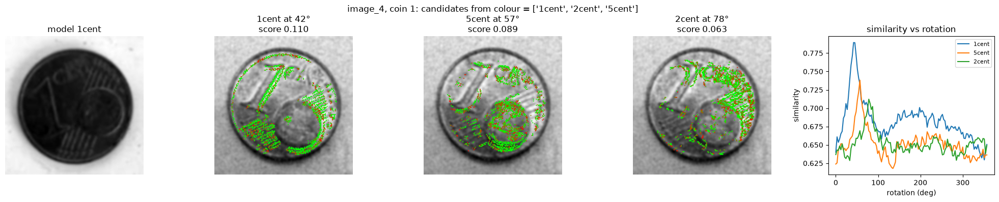

    1cent: score 0.110   best rotation    42°
    5cent: score 0.089   best rotation    57°
    2cent: score 0.063   best rotation    78°
  -> 1cent


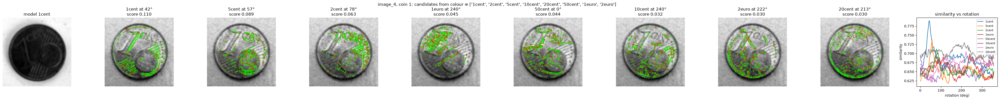

    1cent: score 0.110   best rotation    42°
    5cent: score 0.089   best rotation    57°
    2cent: score 0.063   best rotation    78°
    1euro: score 0.045   best rotation   240°
   50cent: score 0.044   best rotation     0°
   10cent: score 0.032   best rotation   240°
    2euro: score 0.030   best rotation   222°
   20cent: score 0.030   best rotation   213°
  -> 1cent


In [25]:
def show_shape_match(idx, coin=0, candidates=None):
    s, x, y, r = detections[idx][coin]
    if candidates is None:
        candidates = colour_candidates(colour_features(load_target(idx), x, y, r))
    res, crop = shape_match(idx, x, y, r, candidates)
    tgx = cv2.Sobel(crop, cv2.CV_32F, 1, 0, 3); tgy = cv2.Sobel(crop, cv2.CV_32F, 0, 1, 3)
    tang = np.arctan2(tgy, tgx)
    size = crop.shape[0]
    base = cv2.cvtColor(cv2.normalize(crop, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8), cv2.COLOR_GRAY2BGR)

    ranked = sorted(res, key=lambda n: -res[n]['score'])
    fig, axes = plt.subplots(1, len(ranked) + 2, figsize=(4 * (len(ranked) + 2), 4))
    axes[0].imshow(SM_MODEL_IMG[ranked[0]], cmap='gray'); axes[0].set_title(f'model {ranked[0]}'); axes[0].axis('off')
    for ax, name in zip(axes[1:], ranked):
        ox, oy, ang = SM_MODELS[name]
        phi = res[name]['angle']
        px = np.clip(np.round(size / 2 + np.cos(phi) * ox - np.sin(phi) * oy).astype(int), 0, size - 1)
        py = np.clip(np.round(size / 2 + np.sin(phi) * ox + np.cos(phi) * oy).astype(int), 0, size - 1)
        agree = np.abs(np.cos(tang[py, px] - (ang + phi)))
        vis = base.copy()
        for u, v, a in zip(px, py, agree):
            vis[v, u] = (0, int(255 * a), int(255 * (1 - a)))
        ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        ax.set_title(f'{name} at {np.rad2deg(phi):.0f}°\nscore {res[name]["score"]:.3f}'); ax.axis('off')
    for name in ranked:
        axes[-1].plot(np.rad2deg(SM_ANGLES), res[name]['curve'], label=name)
    axes[-1].set_xlabel('rotation (deg)'); axes[-1].set_ylabel('similarity'); axes[-1].legend(fontsize=8)
    axes[-1].set_title('similarity vs rotation')
    plt.suptitle(f'image_{idx}, coin {coin + 1}: candidates from colour = {candidates}')
    plt.tight_layout(); plt.show()
    for name in ranked:
        print(f'  {name:>7}: score {res[name]["score"]:.3f}   best rotation {np.rad2deg(res[name]["angle"]):5.0f}°')
    print(f'  -> {ranked[0]}')


show_shape_match(4)                                   # a well-preserved 1 cent coin
show_shape_match(4, candidates=list(COIN_VALUES))     # same coin, all eight models

---
## 14. Full classification

Classification runs in three steps over the whole target set:

1. **Colour and shape scores for every coin** (14.1). Colour gives the candidates; when more than one
   remains, shape matching scores each of them.
2. **Calibration of the shape scores** (14.2), computed from those scores, without labels.
3. **Decision and output** (14.3) in the format required by the assignment.

In [26]:
COIN_INFO = {}                   # (image, coin index) -> colour features, candidates, raw shape scores
t0 = time.time()
for i in range(1, N_IMAGES + 1):
    img = load_target(i)
    for k, (s, x, y, r) in enumerate(detections[i]):
        f = colour_features(img, x, y, r)
        cands = colour_candidates(f)
        raw = {}
        if len(cands) > 1:
            res, _ = shape_match(i, x, y, r, cands)
            raw = {n: res[n]['score'] for n in cands}
        COIN_INFO[(i, k)] = {'features': f, 'candidates': cands, 'raw': raw}
print(f'{len(COIN_INFO)} coins scored in {time.time() - t0:.0f}s')
print(f'decided by colour alone (1 or 2 euro): {sum(len(v["candidates"]) == 1 for v in COIN_INFO.values())}')

323 coins scored in 138s
decided by colour alone (1 or 2 euro): 65


### 14.2 A bias in the shape scores, and why calibration was not adopted

Inspecting the predictions showed a strong imbalance: with the raw scores, 1 cent was predicted about
a hundred times and 2 cent only about a dozen, and reading the digits of those coins confirmed that
many "1 cent" were in fact 2 or 5 cent. The cause is visible in the table printed below: each model
has its own typical level of prominence, whatever coin it is compared with. The 2 cent model stands
out little on *any* coin, so it almost never wins.

A standard, label-free remedy is calibration: each model's score is expressed relative to the
distribution of that same model's scores over all the coins it was compared with,

$$z_m = \frac{s_m - \mu_m}{\sigma_m}$$

so a model wins when it stands out *more than it usually does*. It carries one implicit assumption,
worth stating: the denominations within a family are treated as equally likely a priori.

**It was not adopted.** Calibration does balance the predictions (the bar chart below), but on
the labelled coins of section 15.2 it did not improve accuracy: computing the statistics over the
coins each model competes on gave 25/51 correct denominations against 29/51 with the raw scores,
and computing them over all coins and all models gave 29/51, the same as raw. A correction whose
effect swings by four coins with a detail of how it is computed is not a reliable improvement, so
the final decision uses the **raw** scores. The imbalance itself remains a documented limitation
(section 17): 1 and 2 cent differ essentially only by the digit, which is the detail the
degradation erases.

  model  coins  mean score     std
  1cent    189       0.044   0.026
  2cent    189       0.027   0.010
  5cent    189       0.038   0.023
 10cent     92       0.048   0.021
 20cent     92       0.041   0.019
 50cent     92       0.045   0.029


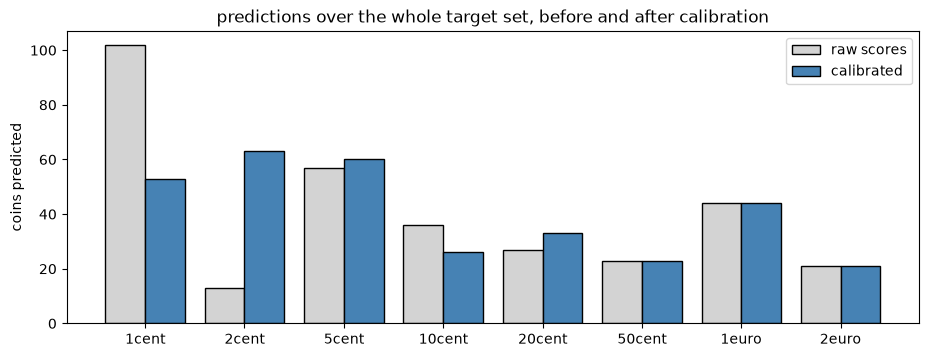

In [27]:
per_model = {n: [] for n in COIN_VALUES}
for info in COIN_INFO.values():
    for n, v in info['raw'].items():
        per_model[n].append(v)
CALIBRATION = {n: (float(np.mean(v)), float(np.std(v))) for n, v in per_model.items() if len(v) > 1}

print(f"{'model':>7}  {'coins':>5}  {'mean score':>10}  {'std':>6}")
for n, (mu, sd) in CALIBRATION.items():
    print(f'{n:>7}  {len(per_model[n]):5d}  {mu:10.3f}  {sd:6.3f}')


def decide(info, calibrated=False):      # final decision: raw scores (see text)
    cands = info['candidates']
    if len(cands) == 1:
        return cands[0]
    if calibrated:
        return max(cands, key=lambda n: (info['raw'][n] - CALIBRATION[n][0]) / CALIBRATION[n][1])
    return max(cands, key=lambda n: info['raw'][n])


order = list(COIN_VALUES)
counts = {mode: [sum(decide(v, mode) == n for v in COIN_INFO.values()) for n in order] for mode in (False, True)}
xpos = np.arange(len(order))
plt.figure(figsize=(11, 3.8))
plt.bar(xpos - 0.2, counts[False], 0.4, label='raw scores', color='lightgrey', edgecolor='k')
plt.bar(xpos + 0.2, counts[True], 0.4, label='calibrated', color='steelblue', edgecolor='k')
plt.xticks(xpos, order); plt.ylabel('coins predicted'); plt.legend()
plt.title('predictions over the whole target set, before and after calibration'); plt.show()

### 14.3 Decision and output

In [28]:
def process_image(idx, verbose=True, debug=False):
    names = []
    for k, (s, x, y, r) in enumerate(detections[idx]):
        info = COIN_INFO[(idx, k)]
        name = decide(info)
        names.append(name)
        if debug:
            f = info['features']
            print(f'  coin {k + 1} at ({x:.0f}, {y:.0f}), r = {r:.1f}')
            if len(info['candidates']) == 1:
                print(f'    colour -> {name} (core minus ring warmth {f["core_warmth"] - f["ring_warmth"]:+.3f})')
            else:
                fam = ('copper' if info['candidates'] == COPPER else 'gold' if info['candidates'] == GOLD
                       else 'copper or gold')
                z = {n: (info['raw'][n] - CALIBRATION[n][0]) / CALIBRATION[n][1] for n in info['candidates']}
                print(f'    colour -> {fam} (redness {f["core_redness"]:+.3f})')
                print('    shape (raw, used / calibrated, not used): '
                      + ', '.join(f'{n} {info["raw"][n]:.3f}/{z[n]:+.2f}' for n in sorted(z, key=lambda n: -info['raw'][n]))
                      + f'  -> {name}')
    if verbose:
        print(f'image_{idx}.jpg - {len(names)} coin(s) found:')
        for k, n in enumerate(names, 1):
            print(f'  Coin {k} {{value: {COIN_VALUES[n]:.3f}}}')
        print(f'  Partial Amount {{value: {sum(COIN_VALUES[n] for n in names):.3f}}}')
    return names


_ = process_image(96, debug=True)

  coin 1 at (196, 413), r = 50.8
    colour -> copper (redness +0.154)
    shape (raw, used / calibrated, not used): 1cent 0.139/+3.64, 5cent 0.056/+0.75, 2cent 0.050/+2.29  -> 1cent
  coin 2 at (620, 570), r = 80.5
    colour -> 2euro (core minus ring warmth +0.131)
  coin 3 at (559, 421), r = 61.6
    colour -> gold (redness +0.032)
    shape (raw, used / calibrated, not used): 10cent 0.044/-0.15, 20cent 0.042/+0.07, 50cent 0.032/-0.46  -> 10cent
  coin 4 at (310, 411), r = 56.3
    colour -> copper or gold (redness +0.112)
    shape (raw, used / calibrated, not used): 1cent 0.037/-0.28, 10cent 0.033/-0.68, 50cent 0.031/-0.49, 2cent 0.028/+0.09, 5cent 0.027/-0.49, 20cent 0.019/-1.18  -> 1cent
  coin 5 at (188, 572), r = 69.8
    colour -> gold (redness +0.063)
    shape (raw, used / calibrated, not used): 20cent 0.055/+0.72, 10cent 0.048/+0.04, 50cent 0.037/-0.28  -> 20cent
  coin 6 at (473, 573), r = 71.4
    colour -> 1euro (core minus ring warmth -0.131)
  coin 7 at (328, 580), r 

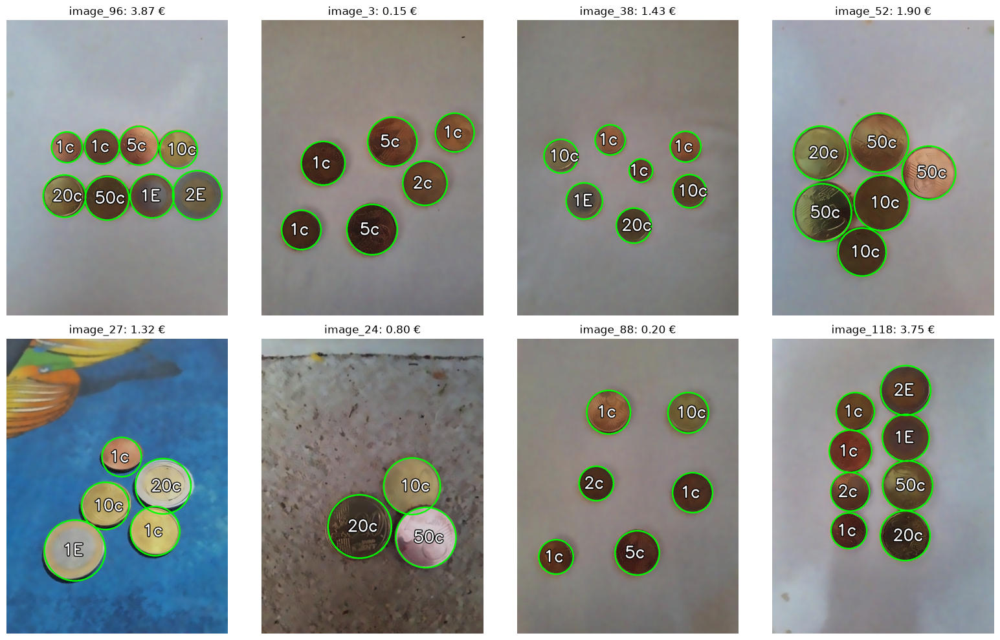

In [29]:
SHORT = {'1cent': '1c', '2cent': '2c', '5cent': '5c', '10cent': '10c',
         '20cent': '20c', '50cent': '50c', '1euro': '1E', '2euro': '2E'}


def show_classification(indices, cols=4):
    rows = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 5 * rows))
    for ax, idx in zip(np.ravel(axes), indices):
        im = load_target(idx).copy()
        names = process_image(idx, verbose=False)
        for (s, x, y, r), n in zip(detections[idx], names):
            cv2.circle(im, (int(x), int(y)), int(r), (0, 255, 0), 4)
            for col, th in [((0, 0, 0), 10), ((255, 255, 255), 3)]:
                cv2.putText(im, SHORT[n], (int(x) - 40, int(y) + 15), cv2.FONT_HERSHEY_SIMPLEX, 1.7, col, th)
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(f'image_{idx}: {sum(COIN_VALUES[n] for n in names):.2f} €'); ax.axis('off')
    for ax in np.ravel(axes)[len(indices):]:
        ax.axis('off')
    plt.tight_layout(); plt.show()


show_classification([96, 3, 38, 52, 27, 24, 88, 118])

In [30]:
all_names, total = {}, 0.0
for i in range(1, N_IMAGES + 1):
    all_names[i] = process_image(i, verbose=True)
    total += sum(COIN_VALUES[n] for n in all_names[i])
print()
print(f'Total Amount: {total:.3f} €')

image_1.jpg - 3 coin(s) found:
  Coin 1 {value: 0.010}
  Coin 2 {value: 0.050}
  Coin 3 {value: 0.050}
  Partial Amount {value: 0.110}
image_2.jpg - 1 coin(s) found:
  Coin 1 {value: 0.010}
  Partial Amount {value: 0.010}
image_3.jpg - 6 coin(s) found:
  Coin 1 {value: 0.010}
  Coin 2 {value: 0.020}
  Coin 3 {value: 0.050}
  Coin 4 {value: 0.010}
  Coin 5 {value: 0.010}
  Coin 6 {value: 0.050}
  Partial Amount {value: 0.150}
image_4.jpg - 1 coin(s) found:
  Coin 1 {value: 0.010}
  Partial Amount {value: 0.010}
image_5.jpg - 1 coin(s) found:
  Coin 1 {value: 0.050}
  Partial Amount {value: 0.050}
image_6.jpg - 1 coin(s) found:
  Coin 1 {value: 0.020}
  Partial Amount {value: 0.020}
image_7.jpg - 3 coin(s) found:
  Coin 1 {value: 0.010}
  Coin 2 {value: 0.050}
  Coin 3 {value: 0.500}
  Partial Amount {value: 0.560}
image_8.jpg - 1 coin(s) found:
  Coin 1 {value: 0.010}
  Partial Amount {value: 0.010}
image_9.jpg - 1 coin(s) found:
  Coin 1 {value: 0.050}
  Partial Amount {value: 0.050}
i

---
## 15. Evaluation

### 15.1 Counting
Measured against the annotated counts of all 142 images.


In [31]:
exact = sum(len(all_names[i]) == GROUND_TRUTH[i] for i in range(1, N_IMAGES + 1))
found = sum(len(all_names[i]) for i in range(1, N_IMAGES + 1))
wrong = [(i, GROUND_TRUTH[i], len(all_names[i])) for i in range(1, N_IMAGES + 1) if len(all_names[i]) != GROUND_TRUTH[i]]
print(f'images with the exact coin count : {exact}/{N_IMAGES}  ({100 * exact / N_IMAGES:.1f}%)')
print(f'coins found                        : {found}  (annotated: {sum(GROUND_TRUTH.values())})')
print(f'images wrong (image, annotated, found): {wrong}')

images with the exact coin count : 137/142  (96.5%)
coins found                        : 323  (annotated: 328)
images wrong (image, annotated, found): [(43, 2, 1), (44, 2, 1), (55, 2, 1), (85, 5, 2), (98, 4, 5)]


### 15.2 Classification

The target set has no denomination labels, so 51 coins were read by eye, only where the digit is
unambiguous. They are identified by position, and are **never used by the pipeline** — only to check
its answers.

How the sample was built matters for how to read the figures:

* 23 coins were chosen because their digit was readable (15 single-coin images and all eight coins of
  `image_96`), mostly on neutral backgrounds;
* 28 were chosen **among the coins predicted 1 or 2 cent**, to investigate the 1 cent excess of
  section 14.2, plus a few gold coins found in the same inspection.

The second group deliberately over-represents one kind of error, so the sample is **not** a random
draw from the dataset and its accuracy is not an unbiased estimate. The shape-matching parameters and
the calibration were also chosen while looking at these coins. The figures are therefore indicative,
with an uncertainty of roughly ±7 percentage points from the sample size alone.

raw scores (final)  : denomination 29/51 (57%)   metal family 44/51 (86%)
calibrated          : denomination 25/51 (49%)   metal family 44/51 (86%)

per family (final):
  copper    : denomination 17/29   family 29/29
  gold      : denomination 6/15   family 9/15
  bimetallic: denomination 6/7   family 6/7


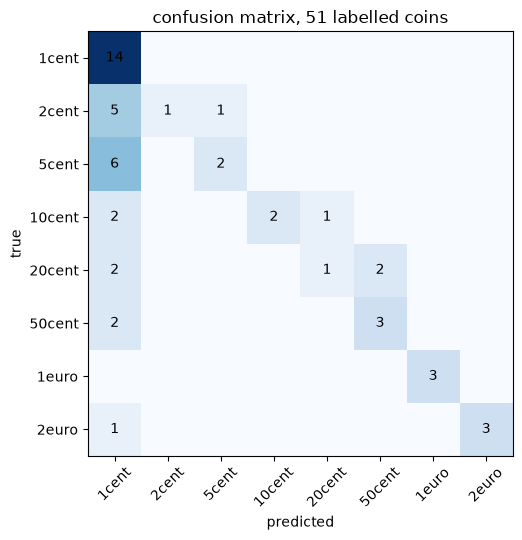

In [32]:
LABELLED = [  # (image, x, y, denomination) - read by eye
    (2, 353, 403, '10cent'), (3, 200, 465, '2cent'), (3, 628, 366, '1cent'), (4, 404, 576, '1cent'),
    (7, 293, 629, '50cent'), (10, 370, 586, '10cent'), (13, 367, 583, '1euro'), (19, 386, 468, '5cent'),
    (20, 431, 445, '1cent'), (22, 386, 553, '2euro'), (27, 374, 386, '5cent'), (30, 498, 486, '1cent'),
    (32, 258, 605, '20cent'), (33, 390, 497, '2cent'), (35, 389, 475, '2cent'), (38, 302, 390, '2cent'),
    (38, 403, 490, '1cent'), (41, 347, 643, '50cent'), (47, 491, 594, '5cent'), (53, 349, 499, '20cent'),
    (57, 442, 446, '50cent'), (57, 254, 462, '10cent'), (57, 398, 690, '2euro'), (61, 336, 386, '2euro'),
    (66, 529, 697, '1cent'), (71, 408, 532, '1euro'), (72, 504, 585, '1cent'), (73, 530, 456, '2cent'),
    (79, 474, 661, '20cent'), (81, 396, 498, '50cent'), (83, 386, 563, '20cent'), (88, 126, 710, '1cent'),
    (88, 297, 239, '5cent'), (92, 320, 370, '1cent'), (93, 418, 582, '10cent'), (94, 344, 456, '1cent'),
    (96, 196, 413, '1cent'), (96, 620, 570, '2euro'), (96, 559, 421, '10cent'), (96, 310, 411, '2cent'),
    (96, 188, 572, '20cent'), (96, 473, 573, '1euro'), (96, 328, 580, '50cent'), (96, 430, 408, '5cent'),
    (106, 458, 516, '5cent'), (111, 413, 748, '1cent'), (111, 218, 467, '5cent'), (112, 205, 492, '5cent'),
    (112, 387, 737, '1cent'), (121, 456, 295, '1cent'), (132, 378, 673, '2cent')]

FAMILY = {n: ('copper' if n in COPPER else 'gold' if n in GOLD else 'bimetallic') for n in COIN_VALUES}


def evaluate(calibrated):
    rows = []
    for i, x, y, true in LABELLED:
        dets = detections[i]
        k = min(range(len(dets)), key=lambda j: np.hypot(dets[j][1] - x, dets[j][2] - y))
        rows.append((i, true, decide(COIN_INFO[(i, k)], calibrated)))
    return rows


for label, cal in [('raw scores (final)', False), ('calibrated', True)]:
    rows = evaluate(cal)
    exact = sum(t == p for _, t, p in rows)
    fam = sum(FAMILY[t] == FAMILY[p] for _, t, p in rows)
    print(f'{label:<20}: denomination {exact}/{len(rows)} ({100 * exact / len(rows):.0f}%)   '
          f'metal family {fam}/{len(rows)} ({100 * fam / len(rows):.0f}%)')

rows = evaluate(False)
print('\nper family (final):')
for f in ['copper', 'gold', 'bimetallic']:
    sub = [(t, p) for _, t, p in rows if FAMILY[t] == f]
    print(f'  {f:<10}: denomination {sum(t == p for t, p in sub)}/{len(sub)}   '
          f'family {sum(FAMILY[t] == FAMILY[p] for t, p in sub)}/{len(sub)}')

cm = np.zeros((8, 8), int)
for _, t, p in rows:
    cm[order.index(t), order.index(p)] += 1
plt.figure(figsize=(6.5, 5.5))
plt.imshow(cm, cmap='Blues')
for a in range(8):
    for b in range(8):
        if cm[a, b]:
            plt.text(b, a, cm[a, b], ha='center', va='center', color='k')
plt.xticks(range(8), order, rotation=45); plt.yticks(range(8), order)
plt.xlabel('predicted'); plt.ylabel('true'); plt.title('confusion matrix, 51 labelled coins')
plt.tight_layout(); plt.show()

---
## 16. What was tried and not adopted

All figures below are on the same hand-labelled coins, with random guessing at 1.75 out of 14
(eight classes).

**SIFT with Lowe's ratio test and RANSAC (L4).** 1–4 correct out of 14 over 144 combinations of
scale, contrast threshold and denoising strength — at chance level. The decisive diagnostic: a target
crop matched against *itself rotated by 37°* gives 473 good matches, against the reference of the
same denomination only 12. SIFT works; the two images are genuinely different at the scale SIFT
looks at. The fine engraving is lost to noise and denoising, and the descriptor is sensitive to the
polarity of the edges, which the lighting of a relief inverts (inverting the target intensities
already changes the count from 12 to 18). Restricting SIFT to the three candidates of the colour
family did not help either: 5 out of 11 at best, with no stable configuration, against 3.7 by chance.

A related pitfall: a homography is fixed by exactly four correspondences, so RANSAC always returns at
least four inliers, even for random matches. A threshold of four inliers therefore accepts noise.
Measured true matches (a reference against itself) give 206–500 inliers.

**Chamfer matching.** 3–4 out of 14. It needs an edge map of the target (Canny), and on faint
noisy engraving that map is unreliable — the very step shape-based matching avoids. It is also not
part of the course material.

**Size.** Within one photograph the apparent scale is constant to about ±1.3% (measured on the
eight coins of `image_96`), so in multi-coin images the denomination can be read from the radius,
once the scale of the image is estimated from all its circles together. It cannot help single-coin
images, where one circle does not determine the scale, and those are 15 of the 23 labelled coins.
On this sample, colour + size scored 14/23 and colour + size + shape matching 14/23, against
16/23 for colour + shape matching alone.

**Coins of 1 € and 2 € as a scale reference.** Bimetallic coins are the most reliable recognition
(colour alone), and within one photograph the apparent scale is constant, so their known diameter can
fix the px/mm of the image and let the other coins be read from their radius. This resolves the
ambiguity of copper-only images, where 1, 2 and 5 cent are spaced by 15% and the whole set of radii
fits equally well if every coin is shifted by one denomination. On clean images it works very well
(`image_96`: 7 of 8). Overall, on the 51 labelled coins it gave 32/51 against 29/51, a difference
within noise, because every earlier error propagates: a coin wrongly taken as 2 € fixes a wrong scale
(`image_30`), a gold coin read as copper on a turquoise background is sized among the wrong
candidates (`image_32`, `image_79`), the oblique view of `image_27` breaks the constant-scale
assumption, and a 4 px error on a radius is enough to swap 20 and 50 cent. A consistency check
(rejecting the anchor when any coin would get an impossible size) also rejected useful anchors
(30/51). Not adopted.

**Calibrated shape scores.** See section 14.2: it balances the predictions across denominations but
does not improve accuracy on the labelled coins (25/51 or 29/51 depending on how the statistics are
computed, against 29/51 raw). Not adopted.

**Linear contrast normalisation, upscaling, other colour channels for SIFT** — none moved SIFT
above 3/14. CLAHE was tested only as an upper bound, being outside the course material, and did
not help either (2/14).

---
## 17. Limitations of the classification

**1 cent is over-predicted.** With raw shape scores about a third of all coins are called 1 cent and
only a few 2 cent. The 2 cent model has a lower typical score than the others (section 14.2), and the
two coins differ essentially only in the digit. Calibration corrects the imbalance but not the
accuracy.

**The engraving is the weak link.** On dark or strongly shaded coins, what survives of the design
is too little for any appearance-based method. Most remaining errors are within a family
(for example 1 cent against 5 cent), where colour gives no help and everything rests on the
engraving.

**Colour depends on a background.** The background annulus assumes the surface around the coin is
visible. Where coins touch, part of the annulus falls on another coin and the reference tint shifts.

**Validation is thin.** 51 coins are enough to show that the method works well above chance, not to
estimate its accuracy precisely; the sample is biased (section 15.2) and the shape-matching
parameters were tuned on it. A larger,
held-out set of labelled coins is the most valuable next step.

**Coloured backgrounds still affect copper against gold.** An earlier version decided *bimetallic*
by comparing each region with the background. On coloured surfaces — in `image_44`, `image_103` and
`image_134` the fabric that looks blue in the stored file is red-orange once the channels are
restored — the background is warmer than the coins, and single-metal coins were read as silver: three
2 € coins in `image_103`, a 1 € and a 2 € on the cent coins of `image_24`, and the spurious circle of
`image_96` reported as 1 € (that circle is now removed by section 12.0). Comparing core with ring instead removes the background from that
decision and corrects all of these. The redness test for copper against gold, however, is still
relative to the background, so on strongly coloured surfaces it can still pick the wrong family.

**Weak silver/gold contrast under coloured light.** In `image_27` the scene is lit through blue
fabric; after the centre refinement the 1 € coin is recognised, but the 2 € coin still shows a
core−ring difference of only +0.066, under the +0.08 threshold, and is classified as a gold coin.

**Size is unused.** In multi-coin images the radius carries information that the current pipeline
ignores. Combining it with shape matching did not pay off on this small, single-coin-heavy sample,
but it remains the most promising addition once a larger evaluation set is available.